This is what I used to load the data from API to json. As the data is being fetched directly from live site, I have downloaded the data to reproduce the same results and also because the original json file was 300.4 MB and exceeded Github upload limit. I have updated the first 2 cells to markdown that saves the data into compressed file.

import requests
import pandas as pd
import warnings

#ignore warnings
warnings.filterwarnings('ignore')

#source data
url = "https://clinicaltrials.gov/api/v2/studies"

all_studies = []
page_token = None

#get upto 10,000 studies/records
while len(all_studies) < 10000:
    params = {
    "query.cond": "lung cancer",
    "pageSize": 1000,
    "format": "json"
    }
    
    if page_token:
        params["pageToken"] = page_token
    
    response = requests.get(url, params=params, timeout=60, verify = False)
    response.raise_for_status()
    
    data = response.json()
    all_studies.extend(data.get("studies", []))
    
    print(f"Loaded {len(all_studies)} studies")
    
    page_token = data.get("nextPageToken")
    if not page_token:
        break

all_studies = all_studies[:10000]
print("Total studies:", len(all_studies))
print(all_studies[0])

#Once the data is loaded, convert to compressed file
import json
import gzip
from pathlib import Path

#Extract fields relevant to trial discovery and potential patient matching.
#Keep the original API JSON separately as a backup; this is a smaller working dataset.

def extract_trial(study):
    p = study.get("protocolSection", {})
    identification = p.get("identificationModule", {})
    status = p.get("statusModule", {})
    design = p.get("designModule", {})
    conditions = p.get("conditionsModule", {})
    eligibility = p.get("eligibilityModule", {})
    description = p.get("descriptionModule", {})
    interventions = p.get("armsInterventionsModule", {})
    locations = p.get("contactsLocationsModule", {})

    return {
        "nct_id": identification.get("nctId"), # Unique trial ID
        "title": identification.get("briefTitle"), # Short study description
        "status": status.get("overallStatus"), # Recruitment status
        "study_type": design.get("studyType"), # Interventional vs observational
        "enrollment": design.get("enrollmentInfo", {}).get("count"),
        "conditions": conditions.get("conditions", []), # Diagnoses/conditions
        "sex": eligibility.get("sex"), # Sex eligibility
        "minimum_age": eligibility.get("minimumAge"), # Age limits
        "maximum_age": eligibility.get("maximumAge"),
        "eligibility_text": eligibility.get("eligibilityCriteria"), # Full inclusion/exclusion text
        "healthy_volunteers": eligibility.get("healthyVolunteers"),
        "study_population": eligibility.get("studyPopulation"),
        "phase": design.get("phases", []),
        "enrollment_type": design.get("enrollmentInfo", {}).get("type"),
        "brief_summary": description.get("briefSummary"),
        "intervention_names": [x.get("name") for x in interventions.get("interventions", [])],
        "locations": [
            {"city": x.get("city"), "state": x.get("state"), "country": x.get("country")}
            for x in locations.get("locations", [])
        ],
        "last_update_posted": status.get("studyFirstPostDateStruct", {}).get("date"),
    }

curated_records = [extract_trial(study) for study in all_studies]
out_file = Path("data/clinical_trials_curated.json.gz")
out_file.parent.mkdir(parents=True, exist_ok=True)
with gzip.open(out_file, "wt", encoding="utf-8", compresslevel=6) as f:
    json.dump(curated_records, f, ensure_ascii=False)

print("Trials exported:", len(curated_records))
print("Fields per trial:", len(curated_records[0]))
print("File size (MB):", round(out_file.stat().st_size / (1024 * 1024), 2))
print("Saved to:", out_file.resolve())

In [6]:
# Load data from compressed json file
import json
import gzip
from pathlib import Path
import pandas as pd

DATA_FILE = Path("data/clinical_trials_curated.json.gz")
if not DATA_FILE.is_file():
    raise FileNotFoundError(
        "Missing data/clinical_trials_curated.json.gz. Run the one-time export cell "
        "in your ORIGINAL notebook and copy the resulting file into the data folder."
    )

with gzip.open(DATA_FILE, "rt", encoding="utf-8") as file:
    records = json.load(file)

print(f"Loaded {len(records)} curated clinical trial records")


Loaded 10000 curated clinical trial records


In [8]:
# Preview a record from the curated dataset.
display(pd.DataFrame(records).head(1).T)

,0
nct_id,NCT01273766
title,Deferasirox in Treating Iron Overload Caused B...
status,COMPLETED
study_type,INTERVENTIONAL
enrollment,16.0
conditions,"[Acute Undifferentiated Leukemia, Adult Acute ..."
sex,ALL
minimum_age,18 Years
maximum_age,None
eligibility_text,Inclusion Criteria:\n\n* Patients must have a ...


In [12]:
# Convert the saved records into a DataFrame.
df = pd.DataFrame(records)
print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (10000, 18)


,nct_id,title,status,study_type,enrollment,conditions,sex,minimum_age,maximum_age,eligibility_text,healthy_volunteers,study_population,phase,enrollment_type,brief_summary,intervention_names,locations,last_update_posted
0,NCT01273766,Deferasirox in Treating Iron Overload Caused B...,COMPLETED,INTERVENTIONAL,16.0,"[Acute Undifferentiated Leukemia, Adult Acute ...",ALL,18 Years,None,Inclusion Criteria:\n\n* Patients must have a ...,False,None,[PHASE2],ACTUAL,RATIONALE: Deferasirox may remove excess iron ...,"[deferasirox, laboratory biomarker analysis, e...","[{'city': 'Winston-Salem', 'state': 'North Car...",2011-01-10
1,NCT06165419,Definitive Radiation for High-Risk Spine Metas...,RECRUITING,INTERVENTIONAL,26.0,"[Metastatic Cancer, Metastatic Lung Cancer, Me...",ALL,18 Years,None,Eligible patients must have:\n\n* Any patholog...,False,None,[PHASE2],ESTIMATED,This study is looking at whether patients with...,[SBRT to the spine],"[{'city': 'Stony Brook', 'state': 'New York', ...",2023-12-11
2,NCT01946100,Treatment of Multifocal Lung Adenocarcinoma,TERMINATED,INTERVENTIONAL,100.0,"[Lung Neoplasms, Carcinoma Non-small-cell Lung...",ALL,18 Years,None,* Patient must be \> 18 years of age\n* Two or...,False,None,[NA],ESTIMATED,To gather preliminary safety and outcome data ...,[Multifocal Lung Adenocarcinoma],"[{'city': 'Rochester', 'state': 'Minnesota', '...",2013-09-19
3,NCT07282444,A New Way to Share Radiation Therapy Plans Bet...,NOT_YET_RECRUITING,INTERVENTIONAL,194.0,"[Lung Carcinoma, Head and Neck Carcinoma]",ALL,18 Years,None,Inclusion Criteria:\n\n* PRACTICE: Must provid...,True,None,[NA],ESTIMATED,This clinical trial tests a new way to share r...,"[Training and Education, Communication Interve...","[{'city': 'Winston-Salem', 'state': 'North Car...",2025-12-15
4,NCT00782366,Predictive Genetic Risk Assessment Trial,COMPLETED,OBSERVATIONAL,26.0,"[Colon Cancer, Lung Cancer, Atrial Fibrillatio...",ALL,18 Years,65 Years,Inclusion Criteria:\n\n* must be established E...,True,Patients and physicians from the Mayo Clinic R...,[],ACTUAL,This proof-of-principle clinical trial at Mayo...,[SNP analysis],"[{'city': 'Rochester', 'state': 'Minnesota', '...",2008-10-31


In [14]:
# understand the dataset

print("Rows and columns:", df.shape)
print("Unique trials:", df["nct_id"].nunique())
# confirm each clinical trial has a unique NCT ID.
print("Duplicate NCT IDs:", df["nct_id"].duplicated().sum())

display(df.isnull().sum().sort_values(ascending=False))

Rows and columns: (10000, 18)
Unique trials: 10000
Duplicate NCT IDs: 0


study_population      7884
maximum_age           7094
minimum_age            395
enrollment_type        281
healthy_volunteers     176
enrollment             166
sex                      4
eligibility_text         3
phase                    0
locations                0
intervention_names       0
brief_summary            0
nct_id                   0
title                    0
conditions               0
study_type               0
status                   0
last_update_posted       0
dtype: int64

In [16]:
# Start EDA with a copy so the original extracted dataframe remains unchanged.
df_clean = df.copy()

print("Dataset information:")
df_clean.info()

print("\nMissing values (%):")
display(
    (df_clean.isnull().mean() * 100)
    .round(2)
    .sort_values(ascending=False)
)


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 18 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   nct_id              10000 non-null  object 
 1   title               10000 non-null  object 
 2   status              10000 non-null  object 
 3   study_type          10000 non-null  object 
 4   enrollment          9834 non-null   float64
 5   conditions          10000 non-null  object 
 6   sex                 9996 non-null   object 
 7   minimum_age         9605 non-null   object 
 8   maximum_age         2906 non-null   object 
 9   eligibility_text    9997 non-null   object 
 10  healthy_volunteers  9824 non-null   object 
 11  study_population    2116 non-null   object 
 12  phase               10000 non-null  object 
 13  enrollment_type     9719 non-null   object 
 14  brief_summary       10000 non-null  object 
 15  intervention_names  10000 non-nul

study_population      78.84
maximum_age           70.94
minimum_age            3.95
enrollment_type        2.81
healthy_volunteers     1.76
enrollment             1.66
sex                    0.04
eligibility_text       0.03
phase                  0.00
locations              0.00
intervention_names     0.00
brief_summary          0.00
nct_id                 0.00
title                  0.00
conditions             0.00
study_type             0.00
status                 0.00
last_update_posted     0.00
dtype: float64

In [18]:
# Convert min_age_years and max_age_years into numeric values
import re
import numpy as np

def age_to_years(value):
    if pd.isna(value):
        return np.nan
    
    match = re.match(
        r"^\s*(\d+(?:\.\d+)?)\s*(Years?|Months?|Weeks?|Days?)\s*$",
        str(value),
        re.IGNORECASE
    )
    
    if not match:
        return np.nan
    
    number = float(match.group(1))
    unit = match.group(2).lower()
    
    if unit.startswith("year"):
        return number
    elif unit.startswith("month"):
        return number / 12
    elif unit.startswith("week"):
        return number / 52.18
    elif unit.startswith("day"):
        return number / 365.25

df_clean["min_age_years"] = (
    df_clean["minimum_age"].apply(age_to_years)
)

df_clean["max_age_years"] = (
    df_clean["maximum_age"].apply(age_to_years)
)

display(
    df_clean[
        ["minimum_age", "min_age_years",
        "maximum_age", "max_age_years"]
    ].head()
)

,minimum_age,min_age_years,maximum_age,max_age_years
0,18 Years,18.0,None,NaN
1,18 Years,18.0,None,NaN
2,18 Years,18.0,None,NaN
3,18 Years,18.0,None,NaN
4,18 Years,18.0,65 Years,65.0


In [20]:
# Extract useful features fro, conditions and eligibility modules
df_clean["condition_count"] = (
    df_clean["conditions"]
    .apply(lambda x: len(x) if isinstance(x, list) else 0)
)

df_clean["condition_text"] = (
    df_clean["conditions"]
    .apply(
        lambda x: "; ".join(x)
        if isinstance(x, list) else ""
    )
)

df_clean["eligibility_word_count"] = (
    df_clean["eligibility_text"]
    .fillna("")
    .str.split()
    .str.len()
)

df_clean["has_lung_cancer_condition"] = (
    df_clean["condition_text"]
        .str.contains(
            r"lung cancer|lung neoplasm|pulmonary carcinoma|"
            r"non.small.cell lung|small.cell lung|"
            r"lung adenocarcinoma",
            case=False,
            regex=True,
            na=False
        )
)

display(
    df_clean[
        ["nct_id", "condition_count",
        "eligibility_word_count",
        "has_lung_cancer_condition"]
    ].head()
)

#Check how many studies are for lung cancer
print("\nExplicit lung cancer condition flag:")
print(
    df_clean["has_lung_cancer_condition"]
    .value_counts()
)


,nct_id,condition_count,eligibility_word_count,has_lung_cancer_condition
0,NCT01273766,136,253,False
1,NCT06165419,8,132,True
2,NCT01946100,3,136,True
3,NCT07282444,2,423,False
4,NCT00782366,11,24,True



Explicit lung cancer condition flag:
has_lung_cancer_condition
True     7697
False    2303
Name: count, dtype: int64


In [22]:
# check the studies with has_lung_cancer_condition = False to ensure they are truly not related to lung cancer

non_matching = df_clean[
~df_clean["has_lung_cancer_condition"]
]

display(
non_matching[
["nct_id", "title", "condition_text"]
].head(20)
)

,nct_id,title,condition_text
0,NCT01273766,Deferasirox in Treating Iron Overload Caused B...,Acute Undifferentiated Leukemia; Adult Acute L...
3,NCT07282444,A New Way to Share Radiation Therapy Plans Bet...,Lung Carcinoma; Head and Neck Carcinoma
6,NCT06296745,Intrathecal Pemetrexed for Leptomeningeal Meta...,Leptomeningeal Metastasis
8,NCT04993677,A Study of SEA-CD40 Given With Other Drugs in ...,"Melanoma; Carcinoma, Non-Small- Cell Lung"
9,NCT01696981,Screening for Colorectal Cancer in Older Patie...,Colon Carcinoma; Rectal Carcinoma
21,NCT06048705,Study of GSK3901961 In Previously Treated Adva...,Neoplasms
31,NCT00780611,Investigating the Improvement in 4D CT Images ...,Cancer of the Lung; Abdominal Cancer
32,NCT00315211,Weekly Topotecan With Docetaxel in Recurrent S...,Mediastinal Neoplasms
33,NCT07079436,EIT Evaluation of Pulmonary Ventilation With D...,Intercostal Nerve Block; Pulmonary Ventilation...
36,NCT03449602,Minirigid Versus Conventional Rigid Thoracosco...,Pleural Effusion


In [24]:
# Check whether some missed records mention lung cancer in their titles.

non_matching = non_matching.copy()

non_matching["lung_cancer_in_title"] = (
non_matching["title"]
.fillna("")
.str.contains(
r"lung cancer|lung neoplasm|"
r"non.small.cell lung|small.cell lung|"
r"lung adenocarcinoma|lung Carcinoma|Cancer of the Lung",
case=False,
regex=True
)
)

print(
non_matching["lung_cancer_in_title"]
.value_counts()
)

lung_cancer_in_title
False    1799
True      504
Name: count, dtype: int64


In [26]:
#improve condition matching to include common synonyms and abbreviations.
import re

lung_cancer_terms = (
    r"lung cancer|"
    r"lung carcinoma|"
    r"lung neoplasm|"
    r"cancer of the lung|"
    r"non.small.cell.lung|"
    r"small.cell.lung|"
    r"\bNSCLC\b|"
    r"\bSCLC\b|"
    r"lung adenocarcinoma|"
    r"pulmonary carcinoma|"
    r"pulmonary neoplasm"
)

df_clean["lung_cancer_match_v2"] = (
    df_clean["condition_text"]
        .fillna("")
        .str.contains(
        lung_cancer_terms,
        case=False,
        regex=True
    )
)

print("Original matching:")
print(df_clean["has_lung_cancer_condition"].value_counts())

print("\nImproved matching:")
print(df_clean["lung_cancer_match_v2"].value_counts())

print("\nNewly identified trials:")
print(
(
    ~df_clean["has_lung_cancer_condition"]
        & df_clean["lung_cancer_match_v2"]
    ).sum()
)

Original matching:
has_lung_cancer_condition
True     7697
False    2303
Name: count, dtype: int64

Improved matching:
lung_cancer_match_v2
True     8196
False    1804
Name: count, dtype: int64

Newly identified trials:
499


Enrollment summary:


count    9.834000e+03
mean     1.816616e+03
std      6.714728e+04
min      0.000000e+00
25%      3.000000e+01
50%      7.000000e+01
75%      2.000000e+02
max      5.940299e+06
Name: enrollment, dtype: float64

Missing enrollment: 166
Zero enrollment: 328


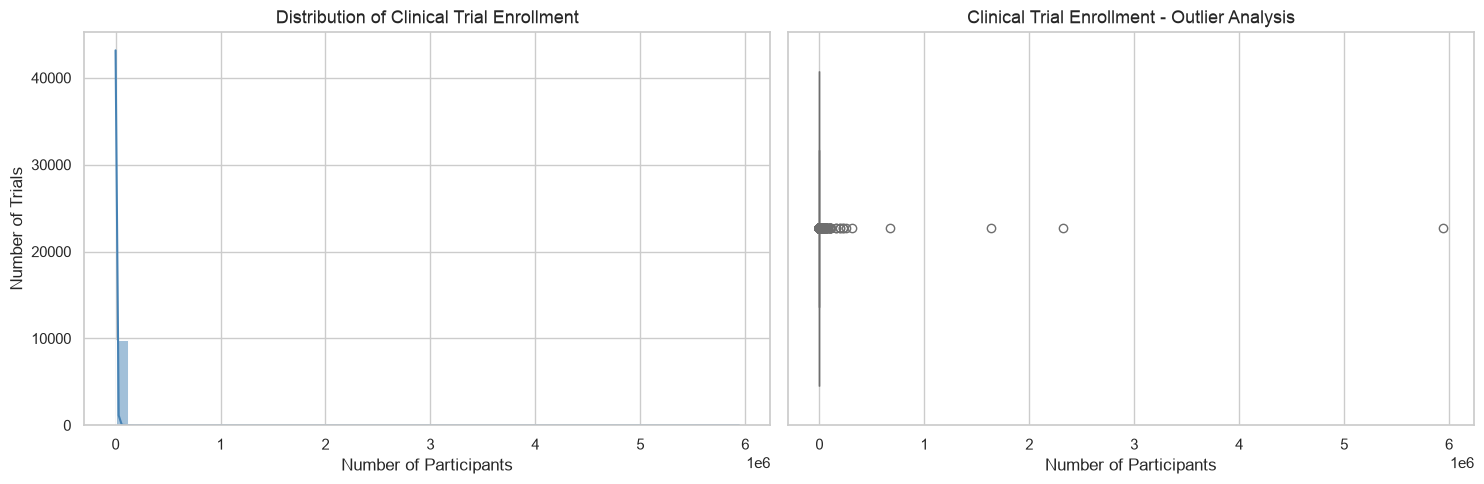

In [30]:
# Explore enrollment statistics and visualize the distribution and possible outliers.
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Enrollment summary statistics
print("Enrollment summary:")
display(df_clean["enrollment"].describe())

print("Missing enrollment:",
df_clean["enrollment"].isna().sum())

print("Zero enrollment:",
(df_clean["enrollment"] == 0).sum())

# Remove missing values for visualization
enrollment_data = df_clean["enrollment"].dropna()

# Create Seaborn visualizations
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: Enrollment distribution
sns.histplot(
    x=enrollment_data,
    bins=50,
    kde=True,
    color="steelblue",
    ax=axes[0]
)

axes[0].set_title(
    "Distribution of Clinical Trial Enrollment",
    fontsize=13
)
axes[0].set_xlabel("Number of Participants")
axes[0].set_ylabel("Number of Trials")

# Plot 2: Enrollment outlier analysis
sns.boxplot(
    x=enrollment_data,
    color="lightcoral",
    ax=axes[1]
)

axes[1].set_title(
    "Clinical Trial Enrollment - Outlier Analysis",
    fontsize=13
)
axes[1].set_xlabel("Number of Participants")

plt.tight_layout()
plt.show()


In [34]:
"""
Number of participants look really odd in the plots, however the Enrollment Summary shows count 9834 so possible some studies have larger number of patients and some have very less.
Inspect the studies with the highest enrollment before deciding how to handle them.
Investigate unusually large enrollment values
Clinical trial enrollment is highly right-skewed, with a median of 70 participants compared with a mean of approximately 1816. 
Extreme values reach nearly 5.94 million participants. 
These values require further investigation by study type before determining whether they should be retained, transformed, or excluded.
"""

largest_trials = df_clean.nlargest(
    15, "enrollment"
    )[
        ["nct_id", "title", "study_type",
        "status", "enrollment"]
    ]

display(largest_trials)

# Compare enrollment across study types
display(
    df_clean.groupby("study_type")["enrollment"]
    .agg(["count", "median", "mean", "max"])
    .round(1)
)


,nct_id,title,study_type,status,enrollment
4109,NCT03847753,Exploring the Comorbidity Between Mental Disor...,OBSERVATIONAL,COMPLETED,5940299.0
635,NCT01236053,Cancer in Patients With Gabapentin (GPRD),OBSERVATIONAL,COMPLETED,2323608.0
2648,NCT04506528,COVID EHR COHORT at the University of Wisconsin,OBSERVATIONAL,COMPLETED,1634381.0
8176,NCT04334239,Effectiveness of Care in Certified Cancer Cent...,OBSERVATIONAL,COMPLETED,670000.0
7729,NCT04125381,Arsenic Exposure and Lung Cancer Incidence,OBSERVATIONAL,COMPLETED,314000.0
8901,NCT05248412,The Long-term Spill-over Impact of COVID-19 on...,OBSERVATIONAL,UNKNOWN,250000.0
4235,NCT07646041,Annual Brain MRI Surveillance for Detection of...,OBSERVATIONAL,COMPLETED,229323.0
4807,NCT03330301,D-tecting Disease - From Exposure to Vitamin D...,OBSERVATIONAL,COMPLETED,222776.0
480,NCT03944447,Outcomes Mandate National Integration With Can...,INTERVENTIONAL,UNKNOWN,200000.0
1623,NCT03987633,EMPOWER-1: A Multi-site Clinical Cohort Resear...,OBSERVATIONAL,RECRUITING,200000.0


,count,median,mean,max
study_type,,,,
EXPANDED_ACCESS,0,NaN,NaN,NaN
INTERVENTIONAL,7691,60.0,301.0,200000.0
OBSERVATIONAL,2143,172.0,7255.8,5940299.0


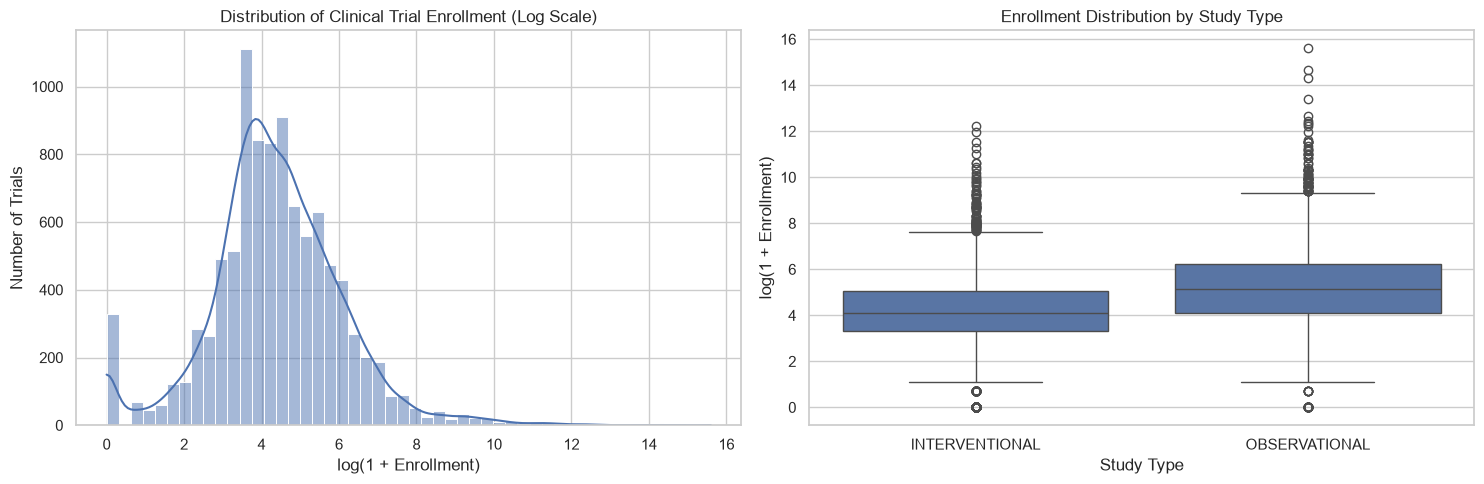

In [38]:
# Log-transform enrollment for clearer plots without changing the original counts.

# Keep original enrollment unchanged
plot_df = df_clean.dropna(
    subset=["enrollment"]
).copy()

# log1p supports zero enrollment values
plot_df["log_enrollment"] = np.log1p(
    plot_df["enrollment"]
)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Distribution on logarithmic scale
sns.histplot(
    data=plot_df,
    x="log_enrollment",
    bins=50,
    kde=True,
    ax=axes[0]
)

axes[0].set_title(
    "Distribution of Clinical Trial Enrollment (Log Scale)"
)
axes[0].set_xlabel("log(1 + Enrollment)")
axes[0].set_ylabel("Number of Trials")

# Boxplot by study type
sns.boxplot(
    data=plot_df,
    x="study_type",
    y="log_enrollment",
    ax=axes[1]
)

axes[1].set_title(
    "Enrollment Distribution by Study Type"
)
axes[1].set_xlabel("Study Type")
axes[1].set_ylabel("log(1 + Enrollment)")

plt.tight_layout()
plt.show()

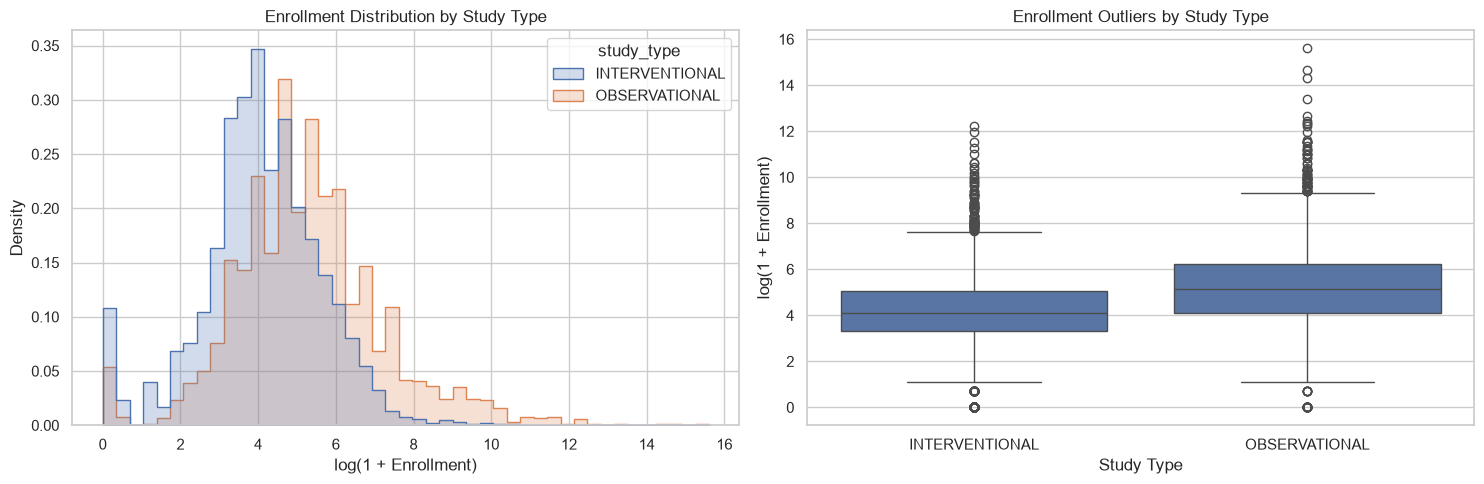

In [40]:
# Compare enrollment patterns separately for observational and interventional studies.
# Observational studies are driving most of the extreme enrollment values, 
# while interventional trials generally have much smaller participant populations.

# Select studies with valid enrollment
plot_df = df_clean[
    df_clean["study_type"].isin(
        ["INTERVENTIONAL", "OBSERVATIONAL"]
    )
    & df_clean["enrollment"].notna()
    & (df_clean["enrollment"] >= 0)
].copy()

# The last plot was hard to visualize so using Log transform - for visualization only
plot_df["log_enrollment"] = np.log1p(
    plot_df["enrollment"]
)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Distribution by study type
sns.histplot(
    data=plot_df,
    x="log_enrollment",
    hue="study_type",
    bins=45,
    element="step",
    stat="density",
    common_norm=False,
    ax=axes[0]
)

axes[0].set_title(
    "Enrollment Distribution by Study Type"
)
axes[0].set_xlabel("log(1 + Enrollment)")
axes[0].set_ylabel("Density")

# Compare enrollment using boxplots
sns.boxplot(
    data=plot_df,
    x="study_type",
    y="log_enrollment",
    ax=axes[1]
)

axes[1].set_title(
    "Enrollment Outliers by Study Type"
)
axes[1].set_xlabel("Study Type")
axes[1].set_ylabel("log(1 + Enrollment)")

plt.tight_layout()
plt.show()

In [42]:
# Check whether zero enrollment is associated with a particular study status.
zero_enrollment = df_clean[
    df_clean["enrollment"] == 0
]

print("Zero enrollment trials by status:")

display(
    zero_enrollment["status"].value_counts()
)

Zero enrollment trials by status:


status
WITHDRAWN    328
Name: count, dtype: int64

In [44]:
# Investigate which types and statuses account for missing enrollment values.
# Analyze missing enrollment by study type and status
missing_enrollment = df_clean[
    df_clean["enrollment"].isna()
]

print("Missing enrollment by study type:")
display(missing_enrollment["study_type"].value_counts())

print("\nMissing enrollment by recruitment status:")
display(missing_enrollment["status"].value_counts())

# Cross-tabulation
display(
    pd.crosstab(
        missing_enrollment["study_type"],
        missing_enrollment["status"]
    )
)


Missing enrollment by study type:


study_type
INTERVENTIONAL     116
EXPANDED_ACCESS     40
OBSERVATIONAL       10
Name: count, dtype: int64


Missing enrollment by recruitment status:


status
COMPLETED                    87
UNKNOWN                      34
NO_LONGER_AVAILABLE          19
APPROVED_FOR_MARKETING       12
AVAILABLE                     7
TERMINATED                    5
TEMPORARILY_NOT_AVAILABLE     2
Name: count, dtype: int64

status,APPROVED_FOR_MARKETING,AVAILABLE,COMPLETED,NO_LONGER_AVAILABLE,TEMPORARILY_NOT_AVAILABLE,TERMINATED,UNKNOWN
study_type,,,,,,,
EXPANDED_ACCESS,12,7,0,19,2,0,0
INTERVENTIONAL,0,0,83,0,0,5,28
OBSERVATIONAL,0,0,4,0,0,0,6



Majority-class dummy
                  precision    recall  f1-score   support

No keyword match       0.00      0.00      0.00       361
   Keyword match       0.82      1.00      0.90      1639

        accuracy                           0.82      2000
       macro avg       0.41      0.50      0.45      2000
    weighted avg       0.67      0.82      0.74      2000


TF-IDF + Logistic Regression
                  precision    recall  f1-score   support

No keyword match       0.46      0.68      0.55       361
   Keyword match       0.92      0.83      0.87      1639

        accuracy                           0.80      2000
       macro avg       0.69      0.75      0.71      2000
    weighted avg       0.84      0.80      0.81      2000


Holdout evaluation (20% test set):
                       model  accuracy  precision  recall    f1
        Majority-class dummy     0.820      0.820   1.000 0.901
TF-IDF + Logistic Regression     0.801      0.921   0.828 0.872


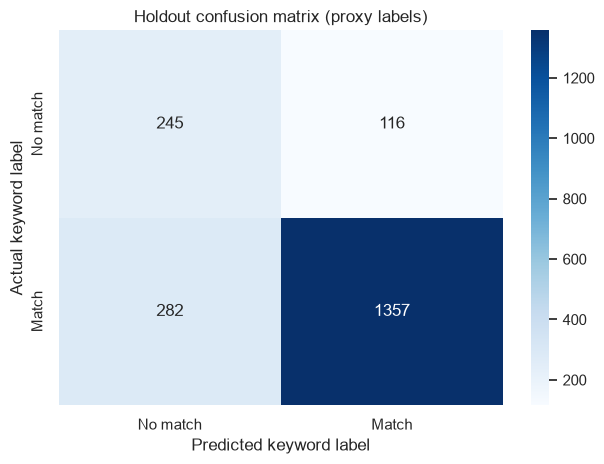


Note: This evaluates prediction of a condition-field keyword flag, NOT clinical relevance or patient-trial eligibility.


In [46]:
# Train a simple text-classification baseline and evaluate it on held-out records.
# Labels are generated from condition keywords, not manually verified patient matches.
#Baseline model
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (classification_report, confusion_matrix,precision_score, recall_score, f1_score, accuracy_score)

required = {'title', 'eligibility_text', 'lung_cancer_match_v2'}
model_df = df_clean.copy()
model_df['model_text'] = (model_df['title'].fillna('') + ' ' +
model_df['eligibility_text'].fillna('')).str.strip()
model_df = model_df[model_df['model_text'].ne('')].copy()
X = model_df['model_text']
y = model_df['lung_cancer_match_v2'].astype(int)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

baseline = Pipeline([
    ('tfidf', TfidfVectorizer(stop_words='english', min_df=2,
        max_features=10000, ngram_range=(1, 2))),
    ('classifier', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42))
])
dummy = DummyClassifier(strategy='most_frequent')
results = []
for name, estimator in [('Majority-class dummy', dummy), ('TF-IDF + Logistic Regression', baseline)]:
    estimator.fit(X_train, y_train)
    predictions = estimator.predict(X_test)
    results.append({
        'model': name,
        'accuracy': accuracy_score(y_test, predictions),
        'precision': precision_score(y_test, predictions, zero_division=0),
        'recall': recall_score(y_test, predictions, zero_division=0),
        'f1': f1_score(y_test, predictions, zero_division=0),
    })
    print(f'\n{name}')
    print(classification_report(y_test, predictions, target_names=['No keyword match', 'Keyword match'], zero_division=0))

scores = pd.DataFrame(results)
print('\nHoldout evaluation (20% test set):')
print(scores.round(3).to_string(index=False))

predictions = baseline.predict(X_test)
cm = confusion_matrix(y_test, predictions, labels=[0, 1])
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
xticklabels=['No match', 'Match'], yticklabels=['No match', 'Match'])
plt.title('Holdout confusion matrix (proxy labels)')
plt.xlabel('Predicted keyword label')
plt.ylabel('Actual keyword label')
plt.tight_layout()
plt.show()

print('\nNote: This evaluates prediction of a condition-field keyword flag, NOT clinical relevance or patient-trial eligibility.')

Model Comparison and Cross-Validation
In my initial analysis, I used TF-IDF and Logistic Regression to predict whether a clinical trial matched the lung cancer terminology filter.

For the final project, I am comparing multiple classification models to see which performs better. I am using stratified 5-fold cross-validation so each model is evaluated on different portions of the training data.

I selected macro F1-score as the main evaluation metric because the two classes are not equally represented. This metric gives equal importance to both classes.

The labels are based on keyword matching rather than confirmed clinical eligibility, so the results represent an initial trial-relevance classification experiment.

In [49]:
import pandas as pd

from sklearn.model_selection import (
train_test_split,
StratifiedKFold,
cross_validate
)

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
#SVC(kernel='linear' was computationally very expensive for my last project so using LinearSVC instead
from sklearn.svm import LinearSVC

# Combine trial title and eligibility text
# These are the text features used to train the models.
X = (
df_clean["title"].fillna("")
+ " "
+ df_clean["eligibility_text"].fillna("")
)

# Use the existing keyword-based label
y = df_clean["lung_cancer_match_v2"].astype(int)

# Keep 20% of the data for final evaluation
X_train, X_test, y_train, y_test = train_test_split(
X,
y,
test_size=0.20,
random_state=42,
stratify=y
)

print("Training records:", len(X_train))
print("Test records:", len(X_test))


Training records: 8000
Test records: 2000


In [51]:
# Define models for comparison
models = {"Dummy Classifier": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=1000,random_state=42),
    "Naive Bayes": MultinomialNB(),
    "Linear SVM": LinearSVC(random_state=42,max_iter=5000)
}

# Use the same 5-fold cross-validation
# for each model
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results = []

for name, model in models.items():

    # Convert text to numerical TF-IDF features
    # within each training fold
    pipeline = Pipeline([
        ("tfidf", TfidfVectorizer(
            max_features=5000,
            stop_words="english"
            )),
        ("model", model)
    ])
    
    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "accuracy": "accuracy",
            "macro_f1": "f1_macro"
        },
        n_jobs=1
    )
    
    results.append({
        "Model": name,
        "Mean Accuracy": scores["test_accuracy"].mean(),
        "Mean Macro F1": scores["test_macro_f1"].mean(),
        "F1 Std Dev": scores["test_macro_f1"].std()
    })

# Compare results in a DataFrame
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="Mean Macro F1",
    ascending=False
)

display(results_df.round(3))


,Model,Mean Accuracy,Mean Macro F1,F1 Std Dev
3,Linear SVM,0.863,0.729,0.011
1,Logistic Regression,0.864,0.681,0.017
2,Naive Bayes,0.841,0.587,0.013
0,Dummy Classifier,0.820,0.450,0.000


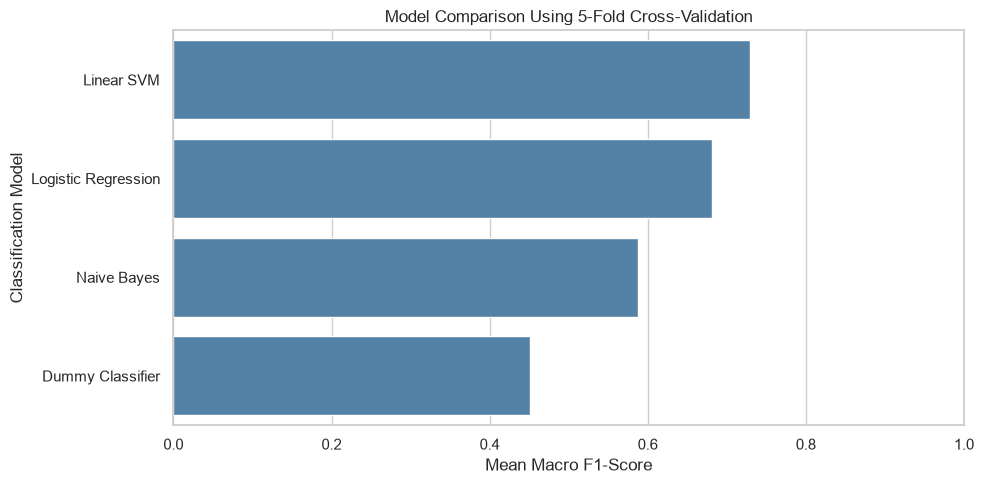

In [61]:
#Visualize the model performance comparision
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_df,
    x="Mean Macro F1",
    y="Model",
    color="steelblue"
)

plt.title("Model Comparison Using 5-Fold Cross-Validation")
plt.xlabel("Mean Macro F1-Score")
plt.ylabel("Classification Model")
plt.xlim(0, 1)

plt.tight_layout()
plt.show()

Hyperparameter Tuning Using GridSearchCV

Linear SVM performed best during model comparison, with a mean macro F1-score of 0.729.

I selected this model for hyperparameter tuning using GridSearchCV. The goal is to find a better combination of TF-IDF and model settings that may improve classification performance.

I am using 5-fold stratified cross-validation and macro F1-score for model selection. The test dataset remains separate and will be used for final evaluation.


In [64]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC

# Create a pipeline for text classification
svm_pipeline = Pipeline([("tfidf", TfidfVectorizer(stop_words="english",max_features=5000)),
    ("model", LinearSVC(random_state=42,max_iter=5000))
])

# Define parameters to test
param_grid = {
    "tfidf__ngram_range": [(1, 1), (1, 2)],
    "tfidf__min_df": [2, 5],
    "model__C": [0.1, 1, 10]
}

# Find the best parameter combination
grid_search = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=param_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=1,
    refit=True
)

# Fit only on training data
grid_search.fit(X_train, y_train)

print("Best parameters:")
print(grid_search.best_params_)

print("\nBest cross-validation macro F1:")
print(round(grid_search.best_score_, 3))

Best parameters:
{'model__C': 1, 'tfidf__min_df': 5, 'tfidf__ngram_range': (1, 1)}

Best cross-validation macro F1:
0.731


In [66]:
# Create a table of GridSearchCV results
tuning_results = pd.DataFrame(grid_search.cv_results_)

display(
    tuning_results[
        ["param_tfidf__ngram_range",
        "param_tfidf__min_df",
        "param_model__C",
        "mean_test_score",
        "std_test_score"]
        ].sort_values(
        "mean_test_score",
        ascending=False
    ).head(10).round(3)
)

,param_tfidf__ngram_range,param_tfidf__min_df,param_model__C,mean_test_score,std_test_score
6,"(1, 1)",5,1.0,0.731,0.012
4,"(1, 1)",2,1.0,0.730,0.012
7,"(1, 2)",5,1.0,0.726,0.009
5,"(1, 2)",2,1.0,0.726,0.010
10,"(1, 1)",5,10.0,0.694,0.009
8,"(1, 1)",2,10.0,0.692,0.010
11,"(1, 2)",5,10.0,0.689,0.014
9,"(1, 2)",2,10.0,0.688,0.014
3,"(1, 2)",5,0.1,0.673,0.016
1,"(1, 2)",2,0.1,0.672,0.016


Best cross-validation macro F1

0.731

Up from 0.729 before tuning (+0.002)

Best hyperparameters

C = 1: Moderate regularization worked best.

min_df = 5: The model ignores terms appearing in fewer than five documents.

ngram_range = (1, 1): Individual words performed better than adding two-word combinations in this search.

Macro F1 = 0.731: The model balances performance across both classes better than the dummy baseline.

Final Model Evaluation
After comparing multiple classification models and tuning Linear SVM using GridSearchCV, I selected the best-performing model for final evaluation.

I used the 20% holdout test dataset that was not used during training, cross-validation, or hyperparameter tuning.

I evaluated the model using accuracy, precision, recall, macro F1-score, and a confusion matrix. Macro F1-score is my main evaluation metric because the dataset has more keyword-matching trials than non-matching trials.

Final tuned Linear SVM results:


,Metric,Score
0,Accuracy,0.855
1,Macro Precision,0.772
2,Macro Recall,0.675
3,Macro F1,0.705



Classification report:
                  precision    recall  f1-score   support

No keyword match       0.67      0.39      0.49       361
   Keyword match       0.88      0.96      0.92      1639

        accuracy                           0.85      2000
       macro avg       0.77      0.68      0.71      2000
    weighted avg       0.84      0.85      0.84      2000



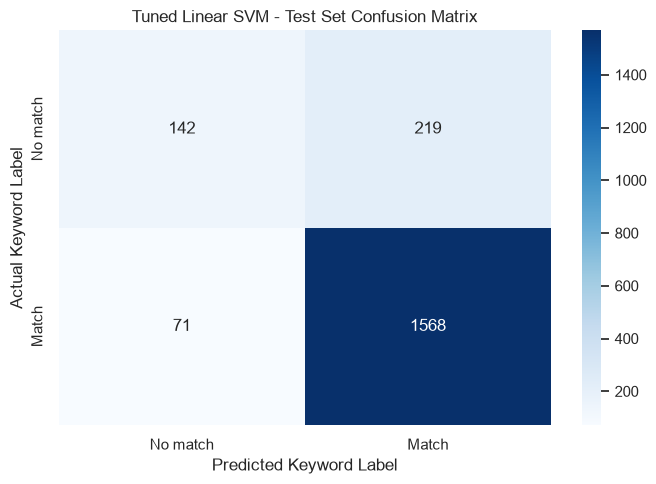

In [70]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,classification_report,confusion_matrix

# Use the best model selected by GridSearchCV
best_model = grid_search.best_estimator_

# Predict on the held-out test dataset
y_pred = best_model.predict(X_test)

# Calculate final evaluation metrics
final_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Macro Precision",
        "Macro Recall",
        "Macro F1"
    ],
    "Score": [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred, average="macro",
        zero_division=0),
        recall_score(y_test, y_pred, average="macro",
        zero_division=0),
        f1_score(y_test, y_pred, average="macro",
        zero_division=0)
    ]
})

print("Final tuned Linear SVM results:")
display(final_results.round(3))

# Show precision, recall, and F1 for each class
print("\nClassification report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["No keyword match", "Keyword match"],
    zero_division=0
))

# Plot the confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No match", "Match"],
    yticklabels=["No match", "Match"]
)

plt.title("Tuned Linear SVM - Test Set Confusion Matrix")
plt.xlabel("Predicted Keyword Label")
plt.ylabel("Actual Keyword Label")

plt.tight_layout()
plt.show()


Findings and Model Interpretation

Model Comparison
I compared four classification models: Dummy Classifier, Logistic Regression, Naive Bayes, and Linear SVM.

I used 5-fold cross-validation and macro F1-score to compare their performance. Linear SVM performed best with a mean macro F1-score of 0.729.

I then used GridSearchCV to tune the Linear SVM model. The best parameter combination improved the cross-validation macro F1-score slightly to 0.731.

Final Evaluation
After tuning, I evaluated the model using the separate test dataset containing 2,000 clinical trials.

The final model achieved:

Accuracy: 85.5%
Macro precision: 0.772
Macro recall: 0.675
Macro F1-score: 0.705
The confusion matrix showed that the model correctly identified 1,568 of 1,639 keyword-matching trials. However, it correctly identified only 142 of 361 non-matching trials.

This suggests that the model is better at recognizing trials that match lung cancer terminology than identifying trials that do not match.

Since most trials in my dataset were labeled as keyword matches, a model could achieve relatively high accuracy by predicting the majority class.= so accuracy alone might not be best evaluation criteria.

Using macro F1-score helped me compare how well the models performed across both classes.

Also, hyperparameter tuning does not always lead to a large improvement. Although GridSearchCV improved the cross-validation score slightly, the final test results showed that there is still room for improvement.

Limitations:

The current model predicts whether trial text is associated with a keyword-based lung cancer relevance label. These labels were created from the condition field rather than independently verified by clinical experts.

The model does not yet determine whether an individual patient meets the inclusion and exclusion criteria of a clinical trial.


Recommendations and Next Steps:

The next step would be to improve how clinical trial eligibility information is understood.

Potential improvements include using medical terminology normalization, extracting information such as disease stage and biomarkers, and comparing patient characteristics with trial eligibility requirements.

It would also be helpful to evaluate the model using a dataset reviewed by clinical experts, so that the results are based on clinical relevance rather than keyword matching alone.

Overall, this project provides an initial foundation for developing a more advanced patient–trial matching approach.